# 08 — Outlier Handling

[Previous](./07_Dimensionality_Reduction.ipynb) | [Repository guide](../README.md) | [Next](./09_Class_Imbalance.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** compare simple ways to limit the influence of unusually large or small numerical values.

`solution.csv` is never read. Outlier limits are learned inside each validation fold.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


In [1]:
# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_backend
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
solution.csv: intentionally not loaded


## 1. What is an outlier?

An **outlier** is far from most observations. It can be an error, a rare real penalty, or a subgroup generated by a different process.

- **IQR rule:** flag values below `Q1 − 1.5×IQR` or above `Q3 + 1.5×IQR`.
- **Clipping:** replace values beyond a limit with the limit.
- **Winsorization:** percentile-based clipping.
- **Indicator:** keep the value and add `was_outlier = 1`.

The IQR table finds one feature at a time. PCA then gives a two-dimensional view of the full numerical profile.


,feature,IQR_outlier_%,lower_limit,upper_limit
9,weak_foot_usage,3.0250,-0.0180,0.7260
8,strong_foot_usage,0.6050,0.2290,0.9970
2,temperature,0.2472,-13.0000,51.0000
1,stadium_capacity,0.1388,-34674.5000,147577.5000
0,referee_strictness,0.0000,-0.5000,1.5000
3,weather_humidity,0.0000,-21.0000,139.0000
5,current_score_diff,0.0000,-8.0000,8.0000
4,minute_taken,0.0000,-53.0000,155.0000
7,goalkeeper_last5_saved_percent,0.0000,-70.0000,170.0000
6,player_last5_scored_percent,0.0000,-70.0000,170.0000


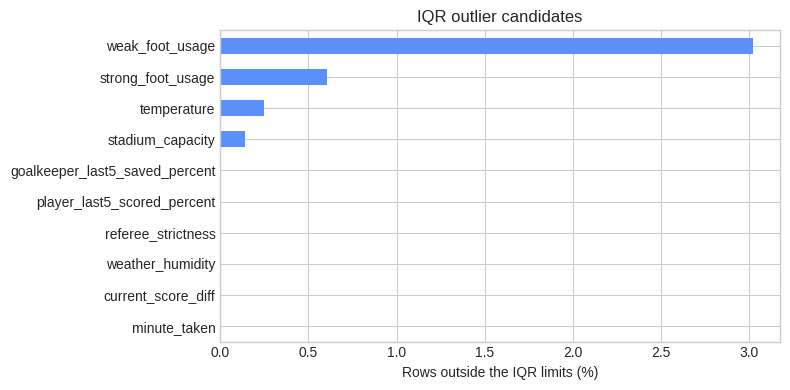

In [4]:
numerical = train.drop(columns=[TARGET] + ID_COLUMNS).select_dtypes(include=np.number)
rows = []
for column in numerical:
    values = numerical[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({
        "feature": column,
        "IQR_outlier_%": values.lt(lower).add(values.gt(upper)).mean() * 100,
        "lower_limit": lower,
        "upper_limit": upper,
    })

outlier_summary = pd.DataFrame(rows).sort_values("IQR_outlier_%", ascending=False)
display(outlier_summary)

plot_data = outlier_summary.head(10).sort_values("IQR_outlier_%")
ax = plot_data.plot.barh(x="feature", y="IQR_outlier_%", figsize=(8, 4), legend=False, color="#5b8ff9", title="IQR outlier candidates")
ax.set(xlabel="Rows outside the IQR limits (%)", ylabel="")
plt.tight_layout()
plt.show()


### PCA visualization inspired by the approach notebook

The organizer’s approach notebook could color points with a private `is_outlier` label. Competitors cannot use that label, so we color only the visible IQR candidates from the most extreme feature. Clear separation helps us inspect a subgroup; it does not prove that removal is correct.


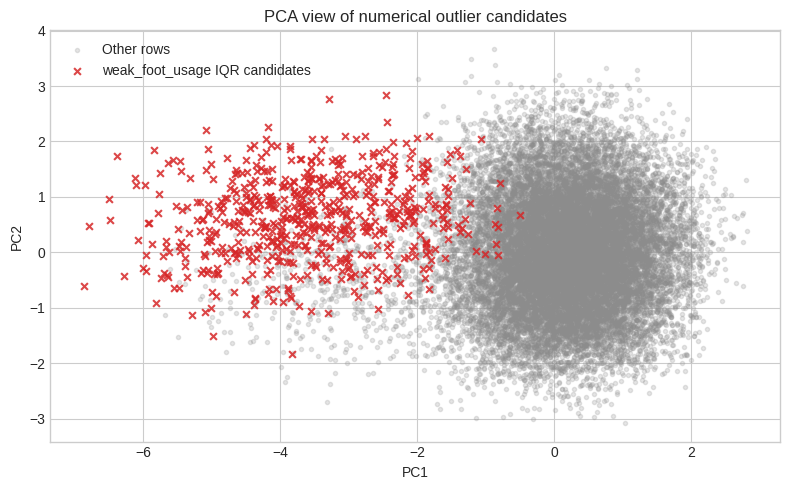

,id,weak_foot_usage,strong_foot_usage,is_scored
8,8,0.8500,0.3500,1
16,16,0.8500,0.4630,1
22,22,0.8300,0.2620,1
45,45,0.8500,0.4930,1
83,83,0.9380,0.4500,1
113,113,0.7520,0.3850,1
177,177,0.8940,0.4280,1
240,240,0.9080,0.3260,1


Example: the highlighted rows are easy to describe, but validation and train/test shift decide what to do with them.


In [5]:
pca_frame = numerical.fillna(numerical.median())
pca_coordinates = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(
    StandardScaler().fit_transform(pca_frame)
)
candidate_feature = outlier_summary.iloc[0]["feature"]
candidate_values = train[candidate_feature]
q1, q3 = candidate_values.quantile([0.25, 0.75])
iqr = q3 - q1
candidate_mask = (candidate_values < q1 - 1.5 * iqr) | (candidate_values > q3 + 1.5 * iqr)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(pca_coordinates[~candidate_mask, 0], pca_coordinates[~candidate_mask, 1],
           s=9, alpha=0.22, color="#8c8c8c", label="Other rows")
ax.scatter(pca_coordinates[candidate_mask, 0], pca_coordinates[candidate_mask, 1],
           s=24, alpha=0.85, marker="x", color="#d62728", label=f"{candidate_feature} IQR candidates")
ax.set(title="PCA view of numerical outlier candidates", xlabel="PC1", ylabel="PC2")
ax.legend()
plt.tight_layout()
plt.show()

display(train.loc[candidate_mask, ["id", candidate_feature, "strong_foot_usage", "is_scored"]].head(8))
print("Example: the highlighted rows are easy to describe, but validation and train/test shift decide what to do with them.")


### What is distribution shift?

**Distribution shift** means the inputs seen during training differ from the inputs where predictions will be used.

Dataset example: an extreme `weak_foot_usage` subgroup appears in train but not in test. Random train folds contain that subgroup in both training and validation, so recognizing it can raise CV F1. Test has no such rows, so the gain may not transfer.

We fit IQR limits on train and compare only feature frequencies in test. No test label and no `solution.csv` is used.


,feature,train_IQR_outlier_%,test_IQR_outlier_%,absolute_gap_pp
9,weak_foot_usage,3.0250,0.0000,3.0250
2,temperature,0.7000,0.0000,0.7000
8,strong_foot_usage,0.6050,0.0000,0.6050
1,stadium_capacity,0.2400,0.0000,0.2400
0,referee_strictness,0.0000,0.0000,0.0000
3,weather_humidity,0.0000,0.0000,0.0000
5,current_score_diff,0.0000,0.0000,0.0000
4,minute_taken,0.0000,0.0000,0.0000
7,goalkeeper_last5_saved_percent,0.0000,0.0000,0.0000
6,player_last5_scored_percent,0.0000,0.0000,0.0000


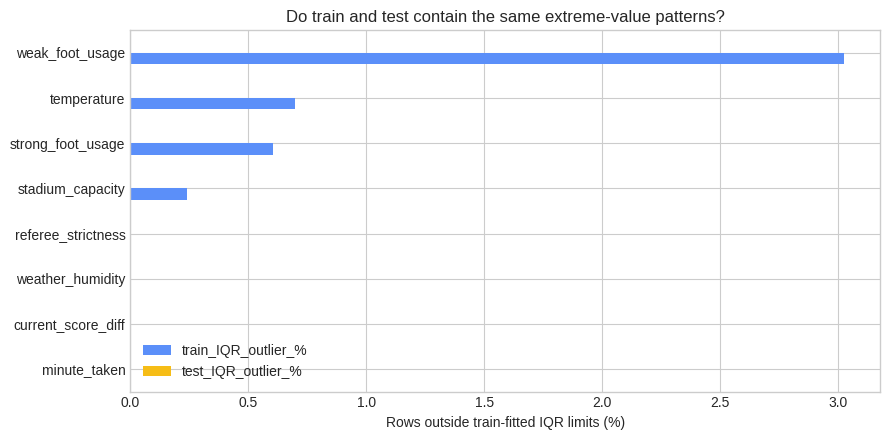

Largest gap: weak_foot_usage | 3.02 percentage points


In [6]:
train_numerical = train.drop(columns=[TARGET] + ID_COLUMNS).select_dtypes(include=np.number)
test_numerical = test[train_numerical.columns]

rows = []
for column in train_numerical:
    train_values = train_numerical[column]
    test_values = test_numerical[column]
    median = train_values.median()
    train_filled = train_values.fillna(median)
    test_filled = test_values.fillna(median)
    q1, q3 = train_filled.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    train_rate = ((train_filled < lower) | (train_filled > upper)).mean() * 100
    test_rate = ((test_filled < lower) | (test_filled > upper)).mean() * 100
    rows.append({
        "feature": column,
        "train_IQR_outlier_%": train_rate,
        "test_IQR_outlier_%": test_rate,
        "absolute_gap_pp": abs(train_rate - test_rate),
    })

shift_summary = pd.DataFrame(rows).sort_values("absolute_gap_pp", ascending=False)
display(shift_summary)

plot_shift = shift_summary.head(8).sort_values("absolute_gap_pp")
ax = plot_shift.plot.barh(
    x="feature",
    y=["train_IQR_outlier_%", "test_IQR_outlier_%"],
    figsize=(9, 4.5),
    color=["#5b8ff9", "#f6bd16"],
    title="Do train and test contain the same extreme-value patterns?",
)
ax.set(xlabel="Rows outside train-fitted IQR limits (%)", ylabel="")
plt.tight_layout()
plt.show()

largest_shift = shift_summary.iloc[0]
print(
    f"Largest gap: {largest_shift['feature']} | "
    f"{largest_shift['absolute_gap_pp']:.2f} percentage points"
)


## 2. Methods to compare

| Method | How it works | Main trade-off |
|---|---|---|
| No handling | Keeps every value unchanged | Preserves information; extremes may influence the model |
| IQR clipping | Clips at the 1.5-IQR limits | Robust rule; may flatten real rare cases |
| 1st–99th percentile clipping | Clips the lowest and highest 1% | Easy to control; always changes some values |
| IQR indicators | Keeps values and adds flags | Preserves extremes; doubles numerical columns |

In [7]:
class IQRClipper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        q1, q3 = np.quantile(X, [0.25, 0.75], axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        return self

    def transform(self, X):
        return np.clip(X, self.lower_, self.upper_)


class PercentileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.lower_ = np.quantile(X, self.lower, axis=0)
        self.upper_ = np.quantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(X, self.lower_, self.upper_)


class IQRIndicatorAdder(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        q1, q3 = np.quantile(X, [0.25, 0.75], axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        return self

    def transform(self, X):
        indicators = ((X < self.lower_) | (X > self.upper_)).astype(float)
        return np.hstack([X, indicators])


In [8]:
FEATURE_GROUPS = {
    "Relative ability": ["skill_advantage", "foot_difference", "skill_ratio_share", "skill_proxy"],
    "Match state": [
        "is_close_game", "is_losing", "is_tied", "is_winning", "match_status",
        "home_crowd_aligned", "is_poor_pitch", "final_extra_time",
    ],
    "Pressure components": ["pressure_index", "low_pressure", "late_minute", "extreme_pressure", "is_weak_player"],
    "Problem interactions": [
        "skill_gap_x_low_pressure", "disaster_combo", "pressure_x_weak",
        "pressure_skill", "keeper_pressure", "late_close_game",
    ],
    "Nonlinear and cyclical": [
        "player_form_squared", "keeper_form_squared", "skill_to_keeper_ratio",
        "score_x_minute", "minute_sin", "minute_cos", "humidity_sq_weak",
        "skill_keeper_product", "humidity_minute_interaction",
    ],
    "Composure proxies": ["clutch_boost", "choke_penalty"],
}


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    # Relative-ability hypotheses.
    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    # Match state: whether the kicker's team is leading, tied, or losing.
    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    # Post-competition reconstruction of the problem's pressure idea.
    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    # Interactions: one condition changes the effect of another.
    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    # Generic suggested candidates: useful to test even when the result rejects them.
    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    # Composure is hidden; skill_proxy is a visible, imperfect substitute.
    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result

engineered_columns = []
for group_columns in FEATURE_GROUPS.values():
    engineered_columns.extend(group_columns)
X_original = train.drop(columns=[TARGET] + ID_COLUMNS)
X = add_engineered_features(X_original)
y = train[TARGET].astype(int)
model_columns = X_original.columns.tolist() + engineered_columns
categorical_columns = X_original.select_dtypes(exclude=np.number).columns.tolist()
numerical_columns = X_original.select_dtypes(include=np.number).columns.tolist() + engineered_columns
continuous_columns = [column for column in numerical_columns if X[column].nunique(dropna=True) > 2]
binary_columns = [column for column in numerical_columns if column not in continuous_columns]
print(f"Continuous columns handled as possible outliers: {len(continuous_columns)}")
print(f"Binary 0/1 columns kept unchanged: {len(binary_columns)}")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Continuous columns handled as possible outliers: 33
Binary 0/1 columns kept unchanged: 11


## 3. Leakage-safe comparison

The clipping limits are pipeline parameters. Each fold calculates them from its training rows only, then applies the same limits to that fold’s validation rows. Binary `0/1` flags are not outliers, so they bypass these methods.

In [9]:
experiments = [
    ("No handling", "passthrough"),
    ("IQR clipping", IQRClipper()),
    ("1st–99th percentile clipping", PercentileClipper()),
    ("IQR indicators", IQRIndicatorAdder()),
]

rows = []
for name, handler in experiments:
    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("outlier_handler", handler),
            ("scaler", StandardScaler()),
        ]), continuous_columns),
        ("binary", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("scaler", StandardScaler()),
        ]), binary_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_columns),
    ])
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)),
    ])

    with parallel_backend("threading"):
        probabilities = cross_val_predict(pipeline, X[model_columns], y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    fold_f1 = [f1_score(y.iloc[index], predictions[index]) for _, index in cv.split(X, y)]
    rows.append({
        "method": name,
        "f1": f1_score(y, predictions),
        "f1_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, probabilities),
    })

results = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(results)


,method,f1,f1_std,precision,recall,accuracy,roc_auc
0,IQR indicators,0.9423,0.0070,0.9479,0.9367,0.9484,0.9852
1,IQR clipping,0.9267,0.0090,0.9369,0.9168,0.9347,0.9775
2,No handling,0.8847,0.0061,0.8916,0.8779,0.8970,0.9625
3,1st–99th percentile clipping,0.8842,0.0057,0.8910,0.8776,0.8966,0.9625


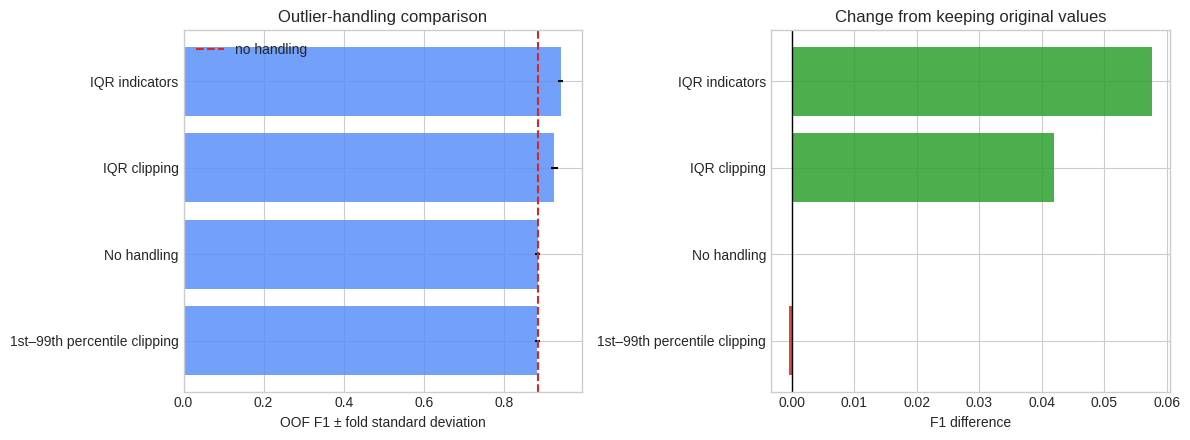

In [10]:
reference = results.loc[results["method"].eq("No handling")].iloc[0]
ordered = results.sort_values("f1")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(ordered["method"], ordered["f1"], xerr=ordered["f1_std"], color="#5b8ff9", alpha=.85)
axes[0].axvline(reference["f1"], color="#d62728", linestyle="--", label="no handling")
axes[0].set(title="Outlier-handling comparison", xlabel="OOF F1 ± fold standard deviation", ylabel="")
axes[0].legend()

deltas = ordered["f1"] - reference["f1"]
axes[1].barh(ordered["method"], deltas, color=np.where(deltas >= 0, "#2ca02c", "#d62728"), alpha=.85)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set(title="Change from keeping original values", xlabel="F1 difference", ylabel="")
plt.tight_layout()
plt.show()


## 4. Decision

The large CV gain must be interpreted with the train/test check. An outlier method can learn a rare training subgroup that is absent from test, so the highest random-CV score is not automatically the safest competition choice.


In [11]:
best = results.iloc[0]
gain = best["f1"] - reference["f1"]
largest_gap = shift_summary["absolute_gap_pp"].max()

print(f"No-handling reference: F1 {reference['f1']:.4f}")
print(f"Best random-CV point estimate: {best['method']} | F1 {best['f1']:.4f} | change {gain:+.4f}")
print(f"Largest train/test outlier-rate gap: {largest_gap:.2f} percentage points")

if gain > 0 and largest_gap >= 1.0:
    print("Decision: keep original values for the competition pipeline.")
    print("Reason: the CV gain is tied to an extreme-value pattern that shifts between train and test.")
else:
    print("Decision: the best method is a reasonable candidate, but confirm it with robustness checks.")


No-handling reference: F1 0.8847
Best random-CV point estimate: IQR indicators | F1 0.9423 | change +0.0576
Largest train/test outlier-rate gap: 3.02 percentage points
Decision: keep original values for the competition pipeline.
Reason: the CV gain is tied to an extreme-value pattern that shifts between train and test.


## Other alternatives

- **Z-score:** flags values many standard deviations from the mean; sensitive to skewed distributions.
- **Modified Z-score:** uses the median and is more robust.
- **Isolation Forest:** isolates unusual multivariate rows with random trees.
- **Local Outlier Factor:** compares each row with nearby neighbors; sensitive to scaling and neighborhood size.
- **One-Class SVM:** learns a boundary around typical rows; can be slow and parameter-sensitive.
- **Elliptic Envelope:** assumes roughly elliptical numerical data; often too restrictive.
- **Row removal:** deletes flagged training cases; can discard real rare events and requires custom fold logic.

These methods are explained but not run because EDA found only mild univariate outlier rates and the simple alternatives answer the immediate question.

In [12]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)
output_path = results_dir / "08_outlier_handling.csv"
results.to_csv(output_path, index=False)
print(f"Saved: {output_path}")


Saved: /kaggle/working/08_outlier_handling.csv


## Why the outlier decision is justified

**Technical evidence:** IQR indicators may raise random-CV F1, but the PCA/feature checks show a distinct subgroup and the key extreme-value rate changes from train to test. Binary indicators are not incorrectly treated as continuous outliers.

**Theoretical reason:** outlier treatment is safe only when the unusual cases represent errors or a process expected at prediction time. Because the strongest signal is train-specific, we keep original values for the competition pipeline and treat the CV jump as a distribution-shift warning.
